# 01 - Exploratory Data Analysis

**Goal:** understand the sessions data, spot quality issues, and form hypotheses about what drives purchases.

**Questions:** How imbalanced is the target? Which behaviours separate buyers from non-buyers? Is anything suspicious (leakage)?

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import logging; logging.disable(logging.INFO)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.config.settings import get_settings
from src.data.loader import load_dataset
S = get_settings()
df = load_dataset(S)
sns.set_theme(style="whitegrid")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Converted
0,1,14.6517,0,0.0000,19,283.8812,0.008014,0.042106,68.579222,0.0,June,1,2,1,1,Returning_Visitor,False,1
1,1,18.9189,2,54.9802,15,1241.7638,0.032395,0.058101,0.000000,0.0,May,2,1,8,12,Returning_Visitor,False,0
2,1,30.0198,0,0.0000,23,365.3384,0.006802,0.029451,0.000000,0.0,Mar,1,2,1,3,New_Visitor,True,0
3,1,6.5566,0,0.0000,6,687.4788,0.039577,0.104395,0.000000,0.6,Dec,1,1,1,2,Returning_Visitor,True,0
4,1,112.5842,1,36.3523,19,656.4535,0.004594,0.038321,0.000000,0.0,Mar,2,1,2,5,Returning_Visitor,False,0


## 1. Data quality
Shape, types, missing values, duplicates, and value ranges.

In [2]:
print('shape:', df.shape)
print('missing cells:', int(df.isna().sum().sum()), '| duplicate rows:', int(df.duplicated().sum()))
df.dtypes.to_frame('dtype').T

shape: (12000, 18)
missing cells: 0 | duplicate rows: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Converted
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,str,int64,int64,int64,int64,str,bool,int64


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12000.0,1.89,1.47,0.0,1.00,2.00,3.00,11.00
Administrative_Duration,12000.0,42.31,49.03,0.0,11.77,28.51,56.38,659.47
Informational,12000.0,0.55,0.75,0.0,0.00,0.00,1.00,6.00
Informational_Duration,12000.0,13.55,25.07,0.0,0.00,0.00,19.93,397.17
ProductRelated,12000.0,19.83,13.17,0.0,11.00,17.00,25.00,156.00
ProductRelated_Duration,12000.0,723.10,763.56,0.0,268.16,499.43,902.04,10154.16
BounceRates,12000.0,0.02,0.02,0.0,0.01,0.02,0.03,0.09
ExitRates,12000.0,0.05,0.03,0.0,0.04,0.05,0.07,0.16
PageValues,12000.0,12.23,25.86,0.0,0.00,0.00,12.91,418.11
SpecialDay,12000.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


**Reading:** no missing values or duplicates. Four columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are stored as integers but are **category codes** - treating them as numbers would imply that Browser 4 is 'twice' Browser 2. We will one-hot encode them.

## 2. Target imbalance

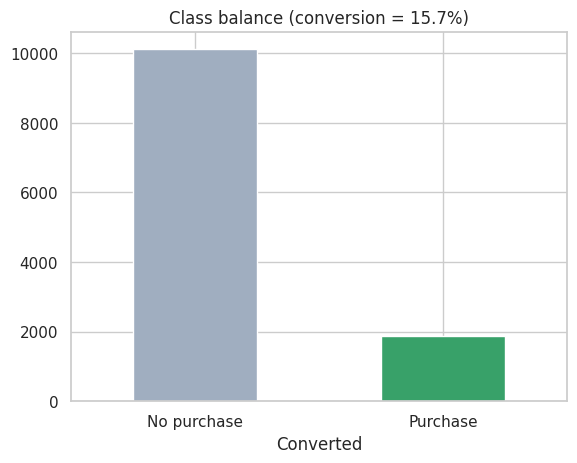

A model that always predicts "no purchase" is 84.3% accurate but finds 0% of buyers.


In [4]:
rate = df['Converted'].mean()
ax = df['Converted'].value_counts().sort_index().plot.bar(color=['#a0aec0', '#38a169'], rot=0)
ax.set_xticklabels(['No purchase', 'Purchase']); ax.set_title(f'Class balance (conversion = {rate:.1%})'); plt.show()
print(f'A model that always predicts "no purchase" is {1-rate:.1%} accurate but finds 0% of buyers.')

**Reading:** only ~15.7% of sessions convert. Accuracy is therefore a trap; we will judge models on **PR-AUC and recall**, and treat imbalance explicitly (SMOTE, class weights, threshold tuning).

## 3. Numeric features by outcome
Several features are heavily right-skewed, so we look at log scale.

{'Administrative_Duration': 2.9, 'Informational_Duration': 3.8, 'ProductRelated_Duration': 3.6, 'PageValues': 4.0}


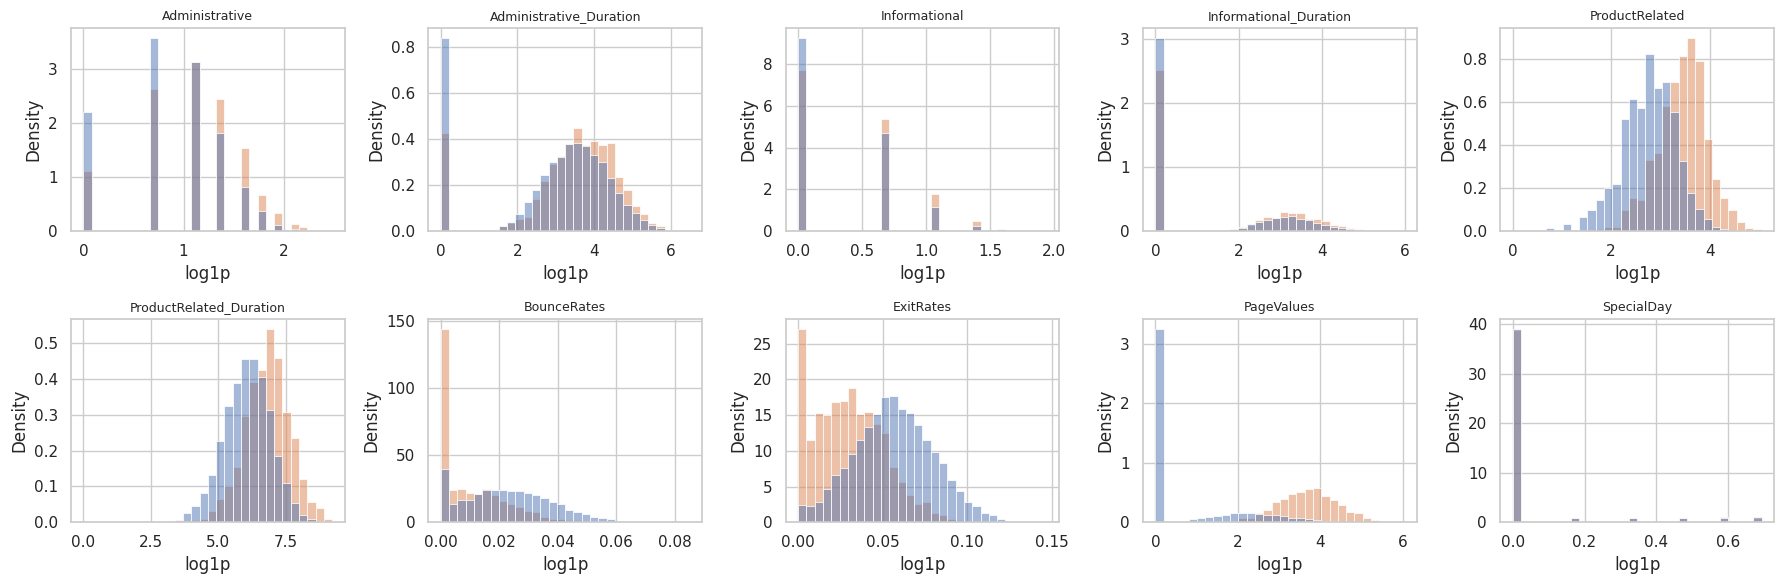

In [5]:
num = S.raw_numeric_columns
print(df[['Administrative_Duration','Informational_Duration','ProductRelated_Duration','PageValues']].skew().round(1).to_dict())
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.ravel(), num):
    sns.histplot(data=df, x=np.log1p(df[col]), hue='Converted', bins=30, stat='density', common_norm=False, ax=ax, legend=False)
    ax.set_title(col, fontsize=9); ax.set_xlabel('log1p')
plt.tight_layout(); plt.show()

In [6]:
df.groupby('Converted')[['PageValues','ExitRates','BounceRates','ProductRelated','ProductRelated_Duration']].median().round(2)

,PageValues,ExitRates,BounceRates,ProductRelated,ProductRelated_Duration
Converted,,,,,
0,0.00,0.06,0.02,15.0,447.74
1,39.49,0.03,0.01,32.0,933.78


**Reading:** buyers view about twice as many product pages, spend about twice as long on them, and have roughly half the exit rate. Skewness (3-4) justifies a `log1p` transform before scaling.

## 4. Correlation with the target

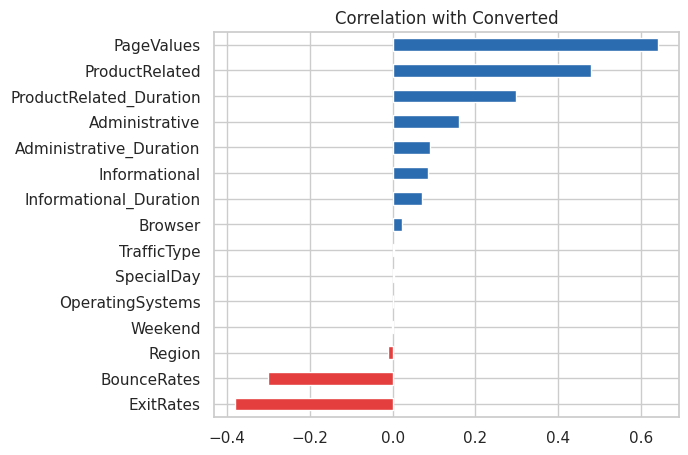

In [7]:
corr = df.corr(numeric_only=True)['Converted'].drop('Converted').sort_values()
corr.plot.barh(figsize=(6, 5), color=['#e53e3e' if v < 0 else '#2b6cb0' for v in corr]); plt.title('Correlation with Converted'); plt.show()

**Reading:** `PageValues` (+0.64) dominates, followed by `ProductRelated` (+0.48); `ExitRates` (-0.38) and `BounceRates` (-0.30) are the strongest negatives. The 'ID' columns (`Region`, `Browser`...) show ~0 *linear* correlation - but that is meaningless for category codes, so we check them as categories below.

## 5. Categorical and calendar effects

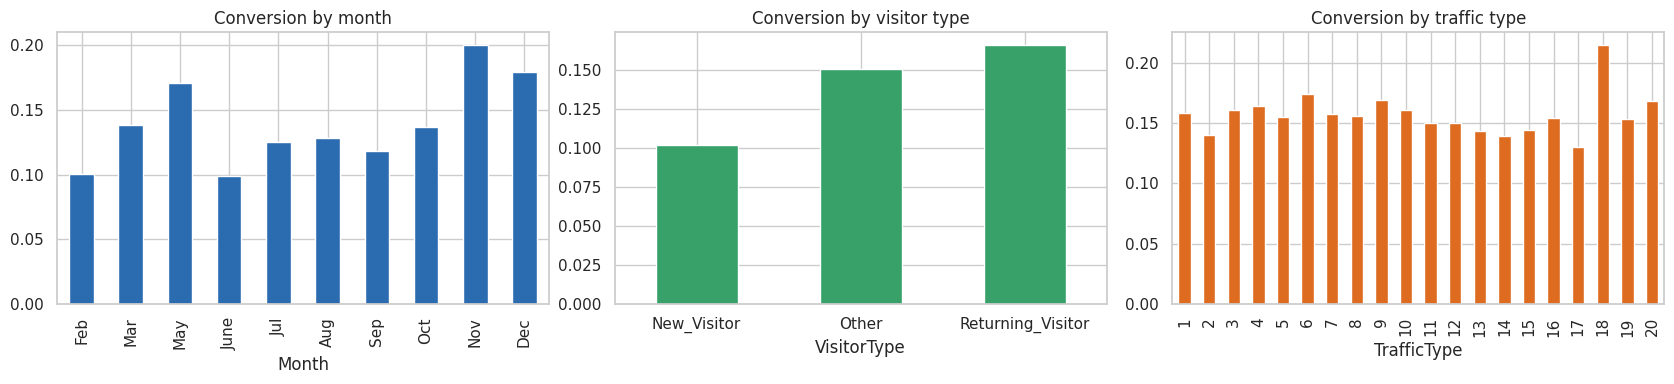

Weekend
False    0.158
True     0.156
Name: Converted, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
order = ['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
df.groupby('Month')['Converted'].mean().reindex(order).plot.bar(ax=axes[0], color='#2b6cb0'); axes[0].set_title('Conversion by month')
df.groupby('VisitorType')['Converted'].mean().plot.bar(ax=axes[1], color='#38a169', rot=0); axes[1].set_title('Conversion by visitor type')
df.groupby('TrafficType')['Converted'].mean().plot.bar(ax=axes[2], color='#dd6b20'); axes[2].set_title('Conversion by traffic type')
plt.tight_layout(); plt.show()
df.groupby('Weekend')['Converted'].mean().round(3)

**Reading:** conversion peaks in **November (20%)** and is lowest in June/Feb (~10%); returning visitors convert at 16.6% vs 10.2% for new visitors; weekend vs weekday makes no difference (15.6% vs 15.8%). Month matters, so we keep it - but note its seasonal nature in the limitations.

## 6. Suspicious feature: `PageValues` (leakage check)

In [9]:
has_pv = (df['PageValues'] > 0).groupby(df['Converted']).mean().rename({0: 'non-buyers', 1: 'buyers'})
print('Share of sessions with PageValues > 0:'); print(has_pv.round(3))

Share of sessions with PageValues > 0:
Converted
non-buyers    0.346
buyers        1.000
Name: PageValues, dtype: float64


**Finding:** **100% of buyers have `PageValues > 0`**, versus 35% of non-buyers. `PageValues` is the average value of pages seen *before a transaction*, so it essentially encodes 'has this session already reached a revenue-generating page'. That makes the model very strong **but late**: the signal is only available near checkout. We therefore (a) keep it as a switch in `config.yaml`, (b) run an ablation with and without it (notebook 03), and (c) document the trade-off in the model card.

## 7. Summary of insights
1. Data is clean; 4 ID columns must be treated as categories.
2. Heavy class imbalance (15.7% positive) -> PR-AUC/recall, not accuracy.
3. Engagement depth (product pages, time on product pages) and low exit/bounce rates separate buyers.
4. `PageValues` is extremely predictive but checkout-proximal -> leakage-style risk to document and ablate.
5. Seasonality (November) and returning-visitor status add moderate signal.